# 05 · Evaluation, Error Analysis & Grad-CAM
**Intel Scene Classification with a CNN Trained From Scratch (TensorFlow / Keras)**  
*Sections 5-6* · MSc Data Science project · Dr. Spoorthi H S

**In this notebook**
- Test accuracy 89.03 %, top-2 97.37 %; test-time augmentation comparison
- Classification report, confusion matrices, ROC and precision-recall curves
- Error analysis: glacier ↔ mountain and buildings ↔ street dominate mistakes
- Grad-CAM heatmaps, final summary, reproducibility checklist

> **How to use these notebooks.** The outputs below come from one complete training run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (configuration, data pipelines, the trained model), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[← Three-Phase Training](04_training.ipynb)

---

---
## 5️⃣ Model Evaluation & Error Analysis

### 5.1 Standard Evaluation (No TTA)

In [ ]:
model.load_weights(CFG["CKPT_PATH"])

# ─── Get predictions on test set ──────────────────────────────────────────────
print("Evaluating on test set …")
eval_results = model.evaluate(test_ds, verbose=0)
test_loss, test_acc = eval_results[0], eval_results[1]
test_top2 = eval_results[2] if len(eval_results) > 2 else None

print(f"\n{'='*55}")
print(f"  Test Loss          : {test_loss:.4f}")
print(f"  Test Accuracy      : {test_acc:.4f}  ({test_acc*100:.2f} %)")
if test_top2 is not None:
    print(f"  Test Top-2 Accuracy: {test_top2:.4f}  ({test_top2*100:.2f} %)")
print(f"{'='*55}")


Evaluating on test set …

  Test Loss          : 1.0602
  Test Accuracy      : 0.8903  (89.03 %)
  Test Top-2 Accuracy: 0.9737  (97.37 %)


### 5.2 Test-Time Augmentation (TTA)

In [ ]:
print(f"Running TTA with {CFG['TTA_STEPS']} augmented passes …")

# ─── TTA augmentation (lighter than training aug) ─────────────────────────────
@tf.function
def tta_augment(img, label):
    img = tf.image.random_flip_left_right(img, seed=None)
    img = tf.image.random_brightness(img, 0.10)
    img = tf.image.random_contrast(img, 0.90, 1.10)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

def make_tta_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.map(normalise,     num_parallel_calls=AUTOTUNE)
    ds = ds.map(tta_augment,   num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

# ─── Accumulate TTA predictions ───────────────────────────────────────────────
tta_preds_acc = None
for step in range(CFG["TTA_STEPS"]):
    tta_ds   = make_tta_dataset(test_p, test_l)
    preds_np = model.predict(tta_ds, verbose=0)
    tta_preds_acc = preds_np if tta_preds_acc is None else tta_preds_acc + preds_np
    if (step+1) % 3 == 0:
        print(f"  TTA step {step+1}/{CFG['TTA_STEPS']}")

tta_preds  = tta_preds_acc / CFG["TTA_STEPS"]
tta_cls    = np.argmax(tta_preds, axis=1)
tta_acc    = np.mean(tta_cls == test_l)

print(f"\n{'='*55}")
print(f"  TTA Test Accuracy  : {tta_acc:.4f}  ({tta_acc*100:.2f} %)")
print(f"  Improvement vs std : +{(tta_acc - test_acc)*100:.2f} pp")
print(f"{'='*55}")


Running TTA with 10 augmented passes …
  TTA step 3/10
  TTA step 6/10
  TTA step 9/10

  TTA Test Accuracy  : 0.8870  (88.70 %)
  Improvement vs std : +-0.33 pp


> **Interpretation.** Test-time augmentation did **not** help: averaging 10 lightly augmented passes gave 88.70 % versus 89.03 % for a single standard pass (-0.33 pp). The flips and colour shifts used for TTA add little information for scene images that are already well centred, so the standard prediction is the one reported. The model reaches **97.37 % top-2 accuracy**, meaning the correct class is almost always among its two highest-ranked guesses.

### 5.3 Classification Report

In [ ]:
# Full predictions for standard model
pred_probs = model.predict(test_ds, verbose=0)
pred_cls   = np.argmax(pred_probs, axis=1)

print("\n── Classification Report (Standard) " + "─"*30)
print(classification_report(test_l, pred_cls,
                              target_names=CFG["CLASSES"], digits=4))

print("── Classification Report (TTA) " + "─"*34)
print(classification_report(test_l, tta_cls,
                              target_names=CFG["CLASSES"], digits=4))



── Classification Report (Standard) ──────────────────────────────
              precision    recall  f1-score   support

   buildings     0.8925    0.8741    0.8832       437
      forest     0.9610    0.9873    0.9740       474
     glacier     0.8733    0.7975    0.8336       553
    mountain     0.8236    0.8629    0.8428       525
         sea     0.8966    0.9353    0.9155       510
      street     0.9036    0.8982    0.9009       501

    accuracy                         0.8903      3000
   macro avg     0.8918    0.8926    0.8917      3000
weighted avg     0.8903    0.8903    0.8898      3000

── Classification Report (TTA) ──────────────────────────────────
              precision    recall  f1-score   support

   buildings     0.8935    0.8833    0.8884       437
      forest     0.9550    0.9852    0.9699       474
     glacier     0.8637    0.7794    0.8194       553
    mountain     0.8177    0.8629    0.8397       525
         sea     0.8902    0.9216    0.9056       51

### 5.4 Confusion Matrix

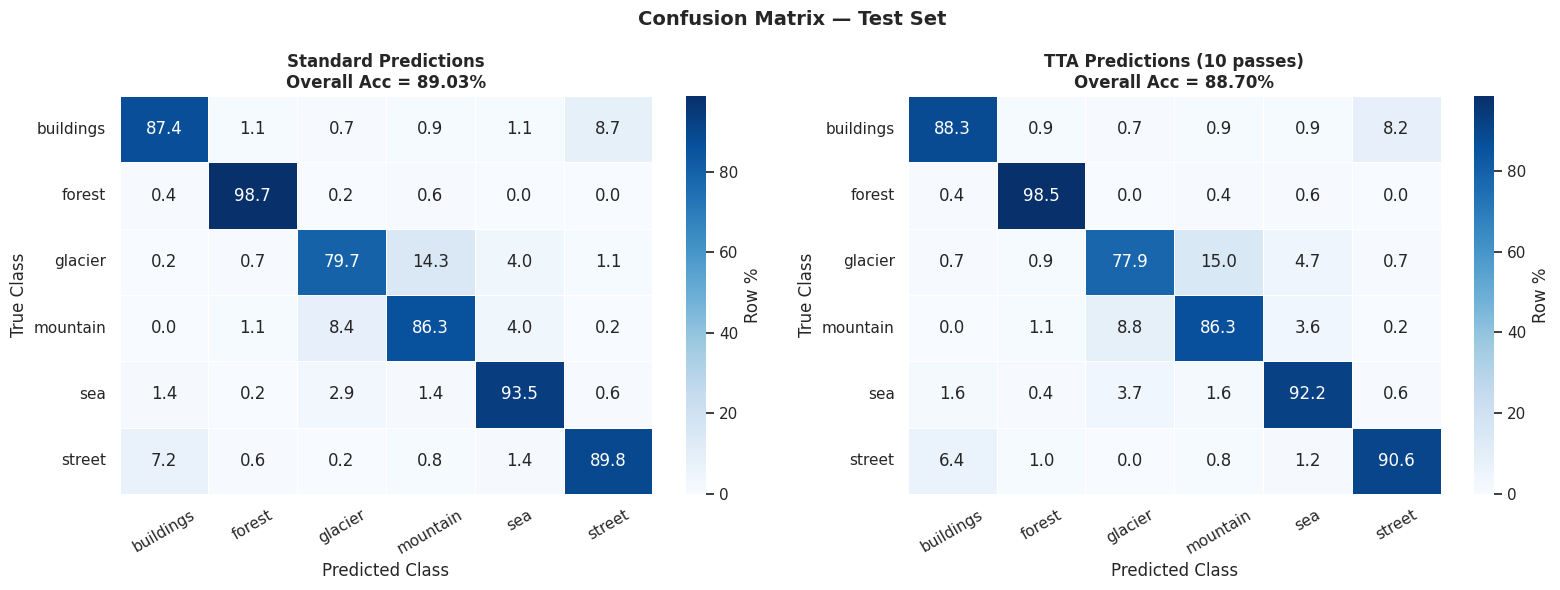

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (preds, title) in zip(axes,[
        (pred_cls, "Standard Predictions"),
        (tta_cls,  f"TTA Predictions ({CFG['TTA_STEPS']} passes)")]):
    cm = confusion_matrix(test_l, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues",
                xticklabels=CFG["CLASSES"],
                yticklabels=CFG["CLASSES"],
                linewidths=0.5, linecolor="white",
                cbar_kws={"label":"Row %"},
                ax=ax)
    ax.set_title(f"{title}\nOverall Acc = {np.trace(cm)/cm.sum()*100:.2f}%",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Class"); ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=30); ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrix — Test Set", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()


### 5.5 ROC Curves (One-vs-Rest)

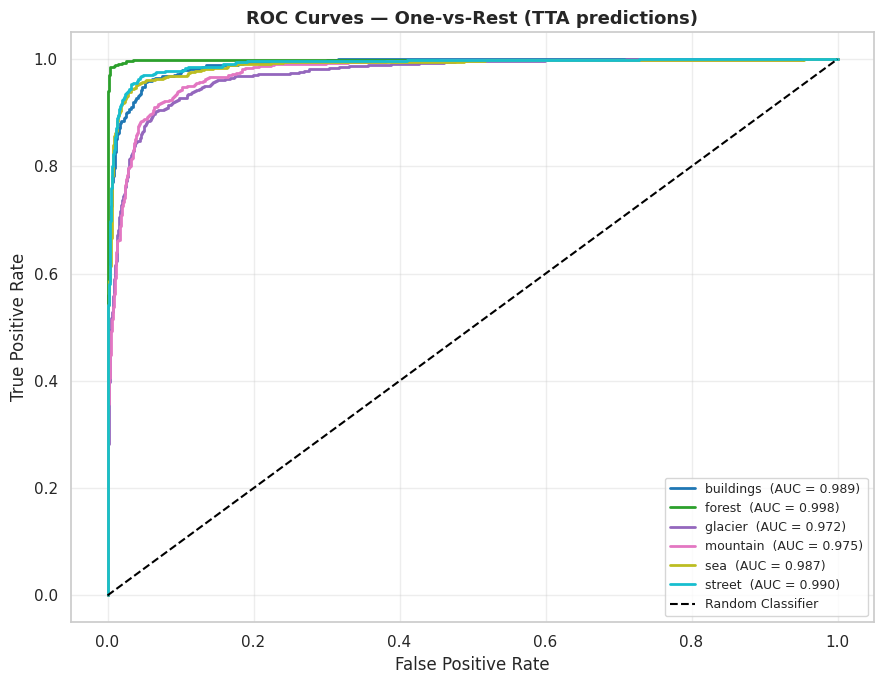

In [ ]:
test_l_bin = label_binarize(test_l, classes=list(range(CFG["NUM_CLASSES"])))

fig, ax = plt.subplots(figsize=(9, 7))
colors  = plt.cm.tab10(np.linspace(0, 1, CFG["NUM_CLASSES"]))

for i, (cls, col) in enumerate(zip(CFG["CLASSES"], colors)):
    fpr, tpr, _ = roc_curve(test_l_bin[:, i], tta_preds[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2, color=col, label=f"{cls}  (AUC = {roc_auc:.3f})")

ax.plot([0,1],[0,1],"k--",lw=1.5, label="Random Classifier")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate",  fontsize=12)
ax.set_title("ROC Curves — One-vs-Rest (TTA predictions)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="lower right"); ax.grid(alpha=0.35)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()


### 5.6 Per-class Precision-Recall Curves

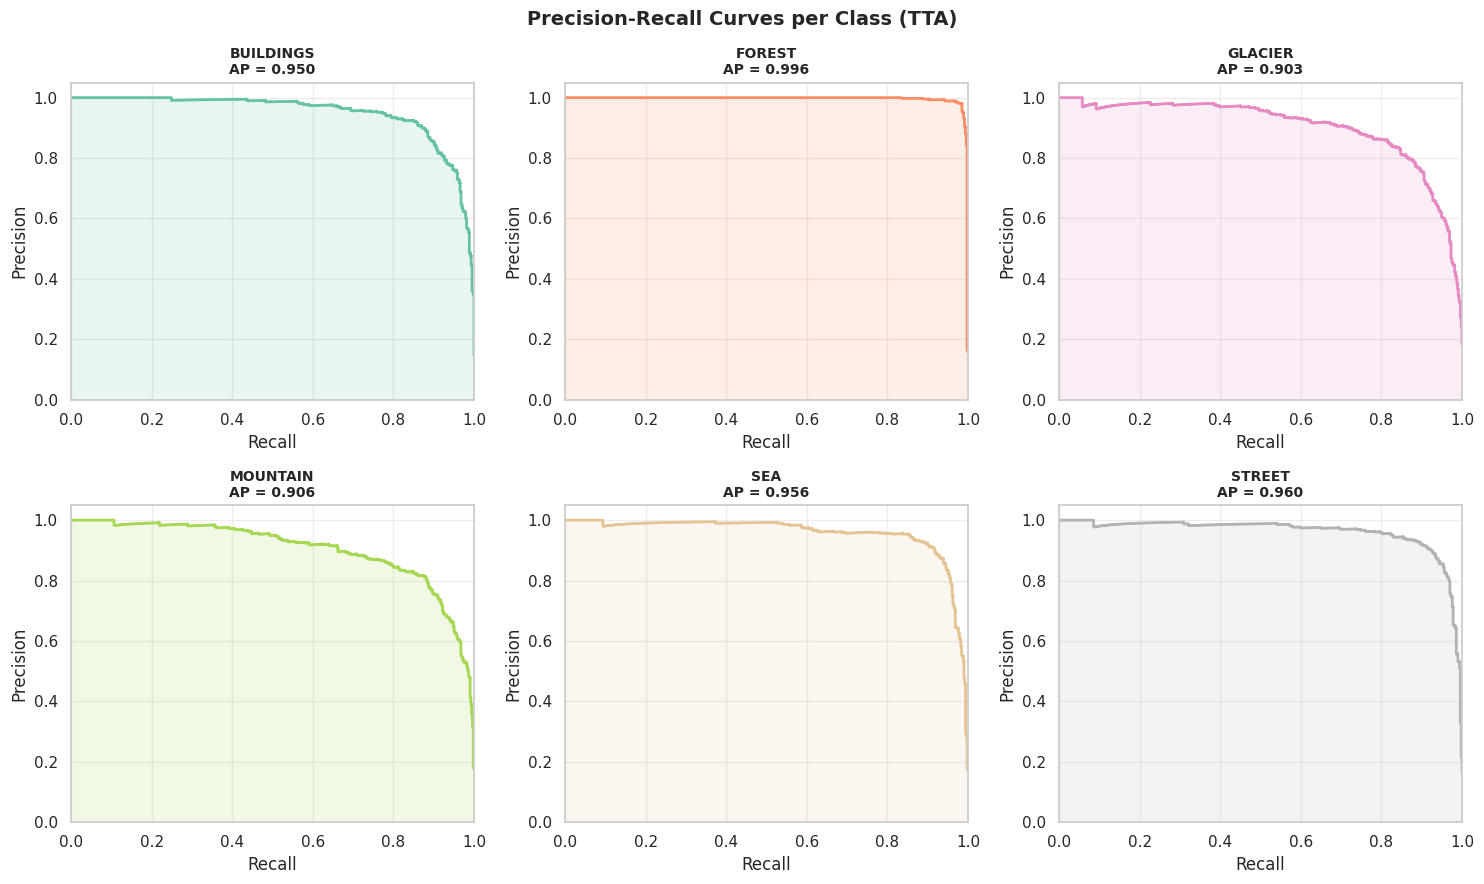

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (i, cls) in zip(axes.flatten(), enumerate(CFG["CLASSES"])):
    prec, rec, _ = precision_recall_curve(test_l_bin[:, i], tta_preds[:, i])
    ap = average_precision_score(test_l_bin[:, i], tta_preds[:, i])

    # Optional: sort for plotting (descending recall)
    rec, prec = rec[::-1], prec[::-1]

    ax.step(rec, prec, lw=2, where="post", color=PALETTE[i])
    ax.fill_between(rec, prec, alpha=0.15, step="post", color=PALETTE[i])
    ax.set_title(f"{cls.upper()}\nAP = {ap:.3f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_xlim(0,1); ax.set_ylim(0,1.05)
    ax.grid(alpha=0.35)

plt.suptitle("Precision-Recall Curves per Class (TTA)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.7 Most Confused Samples (Error Analysis)

In [ ]:
# ─── Collect wrong predictions with confidence ───────────────────────────────
wrong_idx  = np.where(tta_cls != test_l)[0]
confidence = tta_preds[wrong_idx, tta_cls[wrong_idx]]   # confidence in wrong class
# Sort by highest confidence wrong prediction (model most wrong)
sort_ord   = np.argsort(confidence)[::-1]
top_wrong  = wrong_idx[sort_ord[:20]]

print(f"Total test samples   : {len(test_l):,}")
print(f"Misclassified        : {len(wrong_idx):,}")
print(f"Error rate           : {len(wrong_idx)/len(test_l)*100:.2f} %")
print(f"\nTop confused class pairs:")
pairs = [(CFG["CLASSES"][test_l[i]], CFG["CLASSES"][tta_cls[i]]) for i in wrong_idx]
for (true_cls, pred_cls_name), cnt in Counter(pairs).most_common(10):
    print(f"  {true_cls:<12} → {pred_cls_name:<12}  ({cnt} samples)")


Total test samples   : 3,000
Misclassified        : 339
Error rate           : 11.30 %

Top confused class pairs:
  glacier      → mountain      (83 samples)
  mountain     → glacier       (46 samples)
  buildings    → street        (36 samples)
  street       → buildings     (32 samples)
  glacier      → sea           (26 samples)
  mountain     → sea           (19 samples)
  sea          → glacier       (19 samples)
  sea          → mountain      (8 samples)
  sea          → buildings     (8 samples)
  mountain     → forest        (6 samples)


> **Interpretation.** 339 of 3,000 test images (11.3 %) are misclassified, and the errors are highly concentrated. Glacier ↔ mountain confusions alone account for 129 errors (38 % of all mistakes) and buildings ↔ street for 68 (20 %). These pairs share genuine visual content - snow-capped peaks appear in both glacier and mountain scenes, and many street photos are framed by buildings - so many "errors" are images a human could reasonably label either way. Forest is almost never confused (recall 98.7 %).

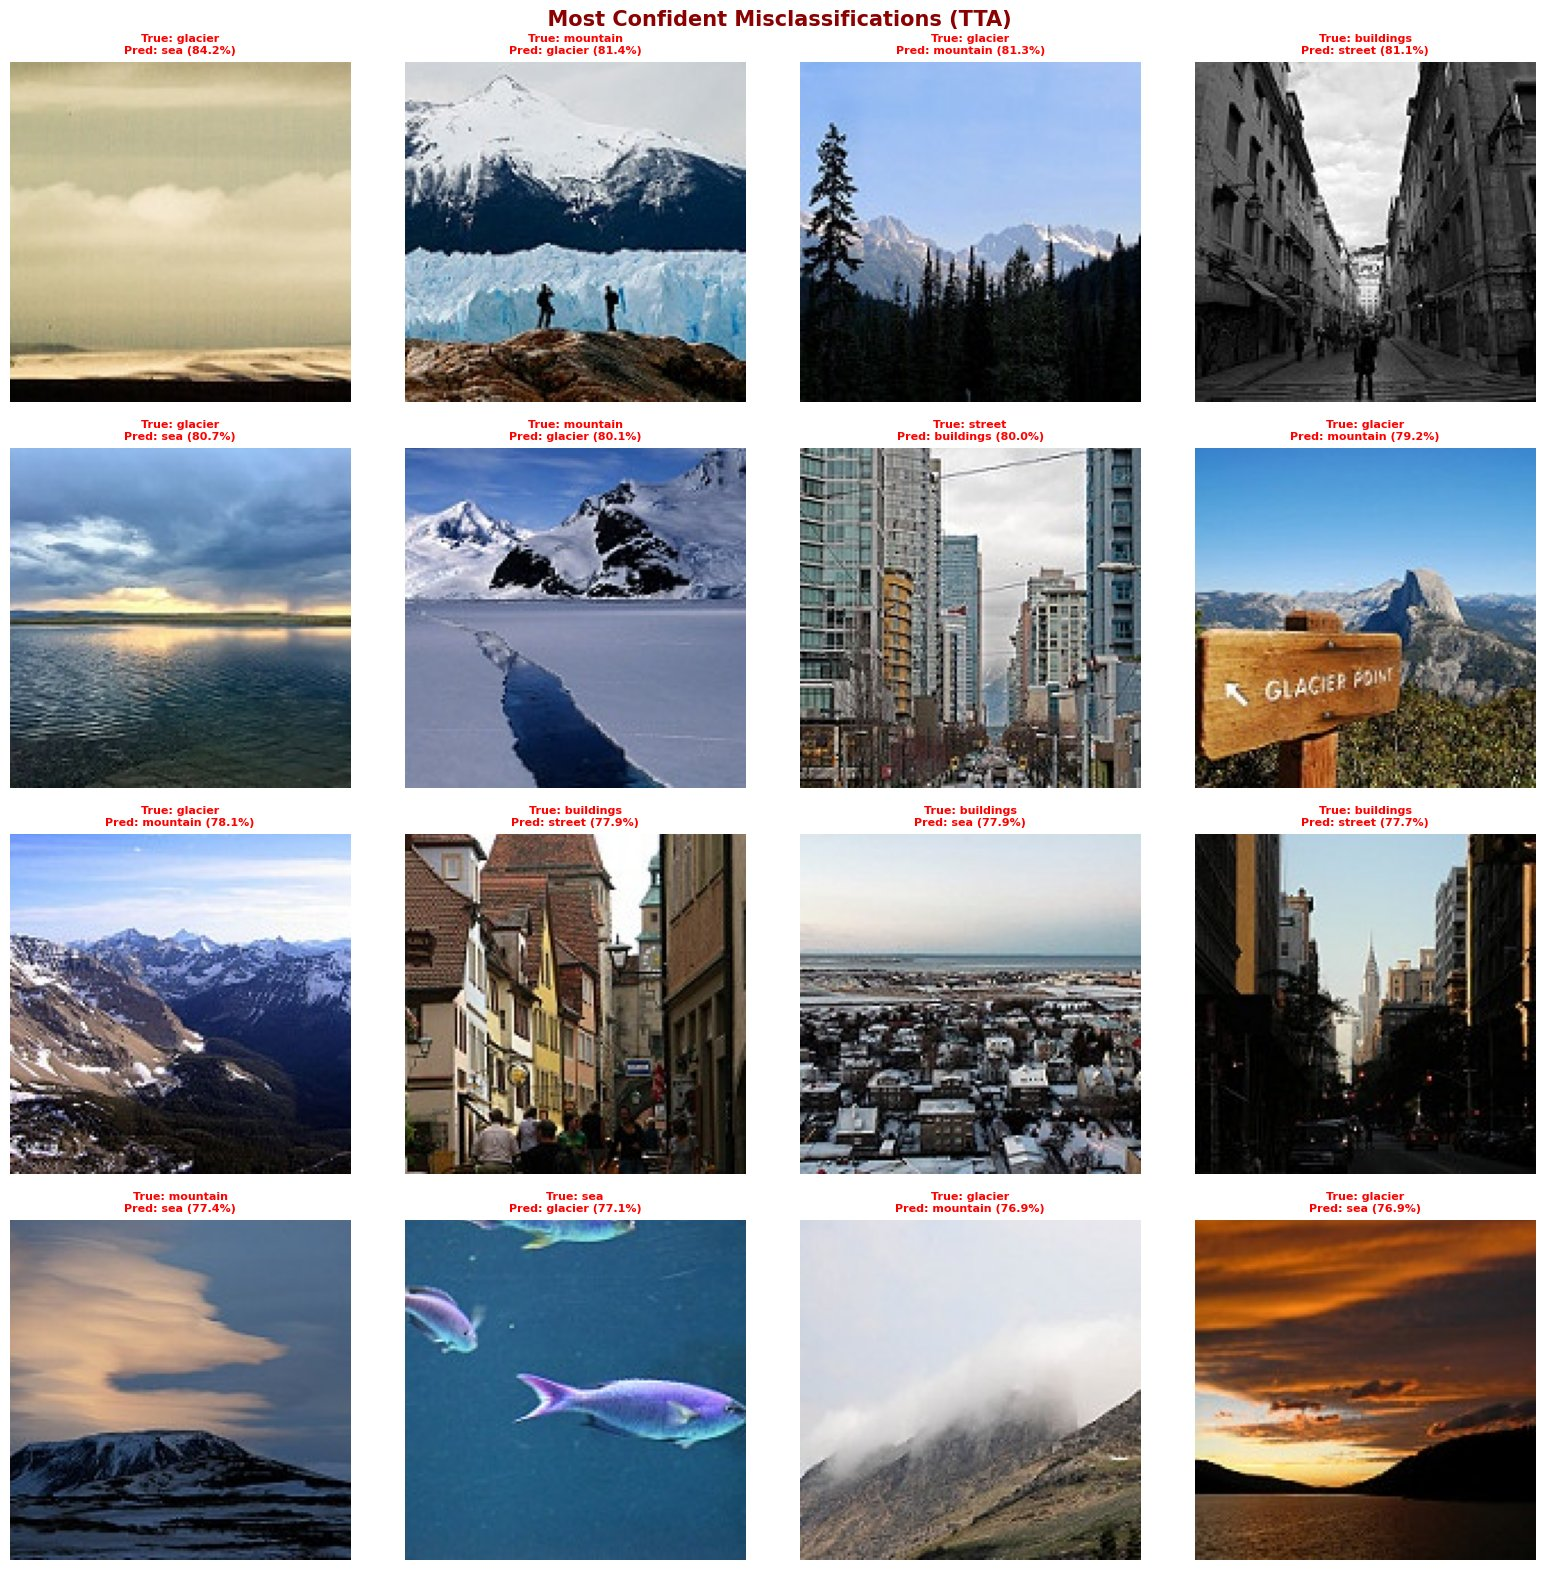

In [ ]:
# ─── Plot most confident wrong predictions ───────────────────────────────────
n_show = 16
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
fig.suptitle("  Most Confident Misclassifications (TTA)",
             fontsize=15, fontweight="bold", color="darkred")

for ax, idx in zip(axes.flatten(), top_wrong[:n_show]):
    img = np.array(Image.open(test_p[idx]).convert("RGB").resize((IMG_SIZE,IMG_SIZE)))
    ax.imshow(img)
    true_cls = CFG["CLASSES"][test_l[idx]]
    pred_c   = CFG["CLASSES"][tta_cls[idx]]
    conf     = tta_preds[idx, tta_cls[idx]] * 100
    ax.set_title(f"True: {true_cls}\nPred: {pred_c} ({conf:.1f}%)",
                 fontsize=8, fontweight="bold",
                 color="red" if true_cls != pred_c else "green")
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_edgecolor("red"); spine.set_linewidth(2.5)

plt.tight_layout()
plt.savefig("misclassified.png", dpi=120, bbox_inches="tight"); plt.show()


### 5.8 Grad-CAM Visualisation (Feature Maps)

In [ ]:
# ─── Grad-CAM implementation ──────────────────────────────────────────────────
import cv2

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """Generate Grad-CAM heatmap for the given image."""
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output,
                 model.output])

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads    = tape.gradient(class_channel, conv_outputs)
    pooled_g = tf.reduce_mean(grads, axis=(0,1,2))
    conv_out = conv_outputs[0]
    heatmap  = conv_out @ pooled_g[..., tf.newaxis]
    heatmap  = tf.squeeze(heatmap)
    heatmap  = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img_path, heatmap, alpha=0.4):
    img     = np.array(Image.open(img_path).convert("RGB").resize((IMG_SIZE,IMG_SIZE)))
    heatmap = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    heatmap = np.uint8(255 * heatmap)
    jet_map = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    jet_rgb = cv2.cvtColor(jet_map, cv2.COLOR_BGR2RGB)
    overlay = (1 - alpha) * img + alpha * jet_rgb
    return np.uint8(np.clip(overlay, 0, 255))

# ─── Find the name of the last Conv2D layer ───────────────────────────────────
last_conv_name = [l.name for l in model.layers if "conv" in l.name.lower()][-1]
print(f"Last conv layer for Grad-CAM: {last_conv_name}")


Last conv layer for Grad-CAM: conv2d_24


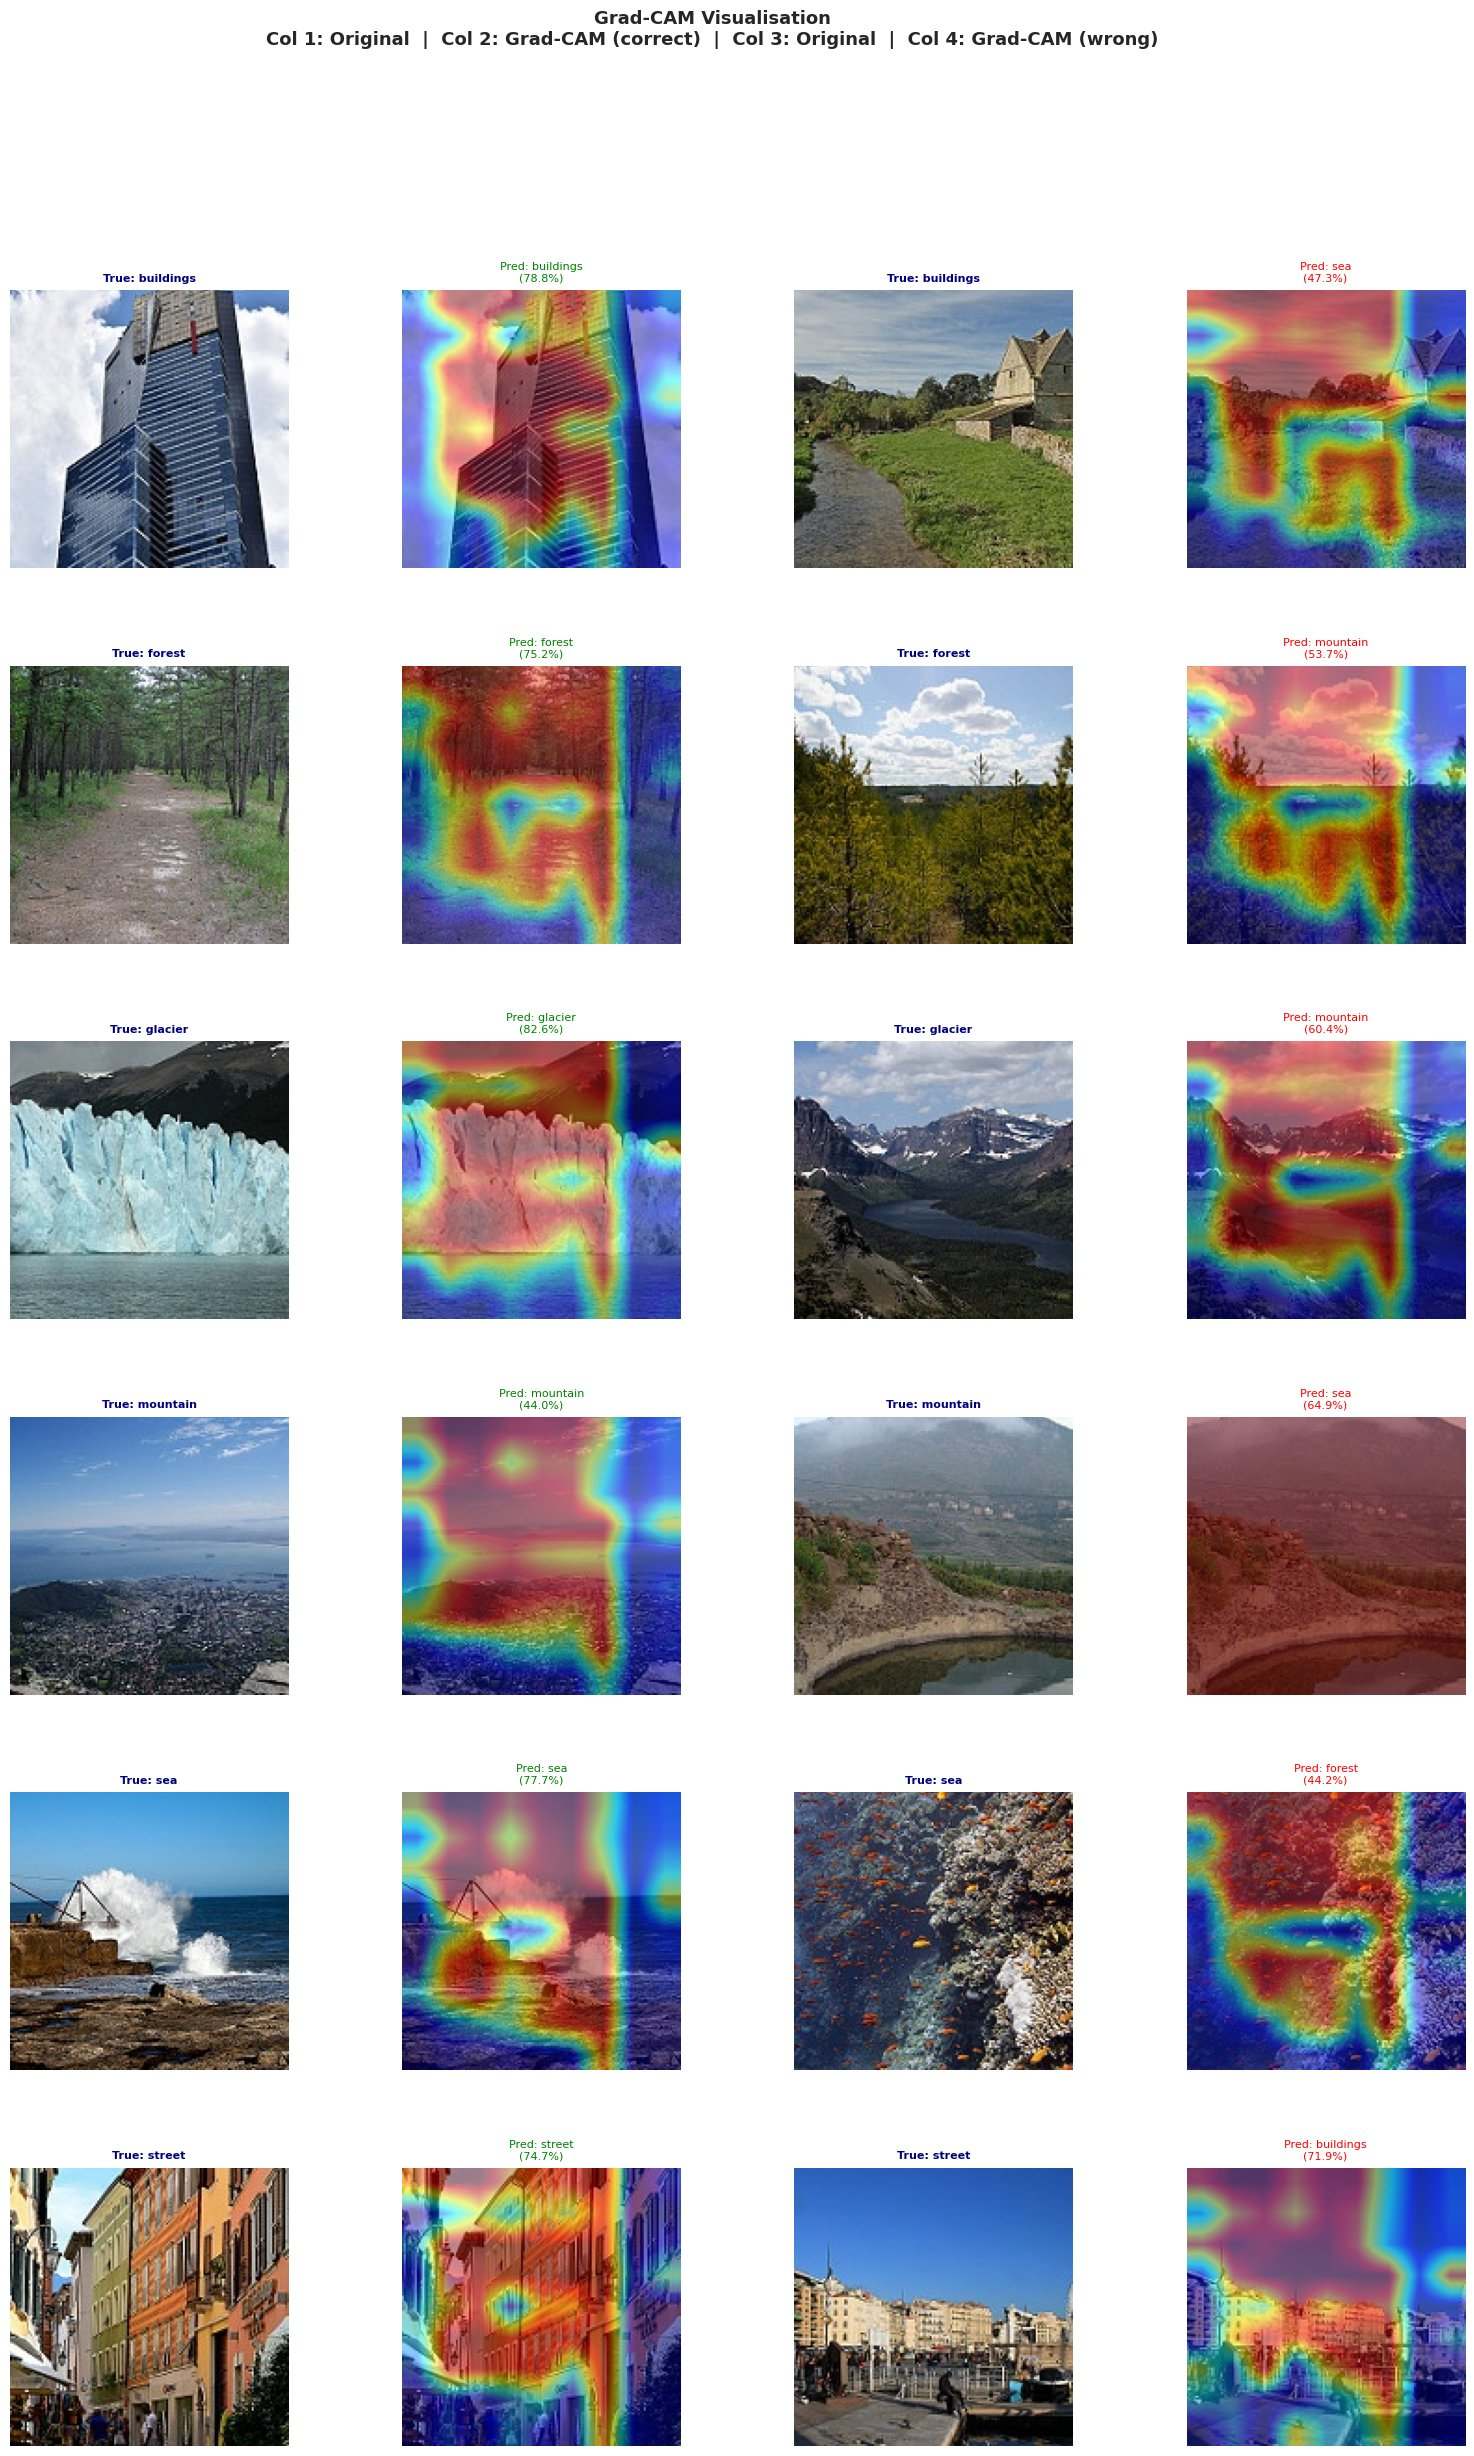

 Grad-CAM grid saved → gradcam_grid.png


In [ ]:
# ─── Full Robust Grad-CAM Grid for Kaggle GPU ─────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import cv2
from matplotlib import gridspec

# -----------------------
# Safe overlay_gradcam function
# -----------------------
def overlay_gradcam(img_path, heatmap, alpha=0.45):
    """Overlay Grad-CAM heatmap on original image with guaranteed valid shape"""
    # Load original image
    img = np.array(Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

    # If heatmap is None or invalid, create a uniform tiny heatmap
    if heatmap is None:
        heatmap = np.ones((IMG_SIZE, IMG_SIZE), dtype=np.float32) * 1e-6
    else:
        # Convert tensor to numpy array
        if isinstance(heatmap, tf.Tensor):
            heatmap = heatmap.numpy()

        heatmap = np.squeeze(heatmap)             # Remove extra dims
        heatmap = np.nan_to_num(heatmap)          # Replace NaN
        if heatmap.size == 0 or np.max(heatmap) == 0:
            heatmap = np.ones((IMG_SIZE, IMG_SIZE), dtype=np.float32) * 1e-6

        # Force heatmap to 2D and correct shape
        if heatmap.ndim != 2:
            heatmap = np.mean(heatmap, axis=-1) if heatmap.ndim > 2 else heatmap
        heatmap = cv2.resize(heatmap.astype(np.float32), (IMG_SIZE, IMG_SIZE))

    heatmap = np.uint8(255 * heatmap)
    jet_map = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(img, 1-alpha, jet_map, alpha, 0)
    return overlay

# -----------------------
# Select one correct & one wrong per class
# -----------------------
correct_idx = {c: None for c in CFG["CLASSES"]}
wrong_idx_d = {c: None for c in CFG["CLASSES"]}

for idx in range(len(test_p)):
    true_c = CFG["CLASSES"][test_l[idx]]
    pred_c = CFG["CLASSES"][tta_cls[idx]]

    if correct_idx[true_c] is None and true_c == pred_c:
        correct_idx[true_c] = idx
    if wrong_idx_d[true_c] is None and true_c != pred_c:
        wrong_idx_d[true_c] = idx
    if all(v is not None for v in correct_idx.values()) and \
       all(v is not None for v in wrong_idx_d.values()):
        break

# -----------------------
# Plot Grad-CAM Grid
# -----------------------
fig = plt.figure(figsize=(20, 28))
fig.suptitle(
    "Grad-CAM Visualisation\nCol 1: Original  |  Col 2: Grad-CAM (correct)  |  "
    "Col 3: Original  |  Col 4: Grad-CAM (wrong)",
    fontsize=13, fontweight="bold"
)
gs = gridspec.GridSpec(len(CFG["CLASSES"]), 4, figure=fig, hspace=0.35, wspace=0.05)

for row, cls in enumerate(CFG["CLASSES"]):
    c_idx = correct_idx[cls]
    w_idx = wrong_idx_d[cls]

    for col, (sel_idx, tag) in enumerate([(c_idx,"ORIG"), (c_idx,"HEATMAP"),
                                           (w_idx,"ORIG"), (w_idx,"HEATMAP")]):
        if sel_idx is None:
            continue

        ax  = fig.add_subplot(gs[row, col])
        img_raw = np.array(Image.open(test_p[sel_idx]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

        if tag == "HEATMAP":
            # Compute heatmap on GPU safely
            img_tf  = tf.cast(img_raw, tf.float32)[tf.newaxis] / 255.0
            hm      = make_gradcam_heatmap(img_tf, model, last_conv_name,
                                           pred_index=tta_cls[sel_idx])
            # Overlay safely
            disp    = overlay_gradcam(test_p[sel_idx], hm, alpha=0.45)
            ax.imshow(disp)
            pc = CFG["CLASSES"][tta_cls[sel_idx]]
            ax.set_title(f"Pred: {pc}\n({tta_preds[sel_idx, tta_cls[sel_idx]]*100:.1f}%)",
                         fontsize=8, color="green" if tta_cls[sel_idx]==test_l[sel_idx] else "red")
        else:
            ax.imshow(img_raw)
            ax.set_title(f"True: {cls}", fontsize=8, fontweight="bold", color="navy")

        ax.axis("off")

plt.savefig("gradcam_grid.png", dpi=110, bbox_inches="tight")
plt.show()
print(" Grad-CAM grid saved → gradcam_grid.png")

### 5.9 Final Results Summary

In [ ]:
print("\n" + "═"*60)
print("   FINAL RESULTS SUMMARY — Intel Image CNN (Scratch)")
print("═"*60)
print(f"  Model             : DeepSceneNet (Custom CNN)")
print(f"  Parameters        : {model.count_params():,}")
print(f"  Transfer Learning : NONE (trained from scratch)")
print(f"  Input size        : {IMG_SIZE}×{IMG_SIZE}×3")
print(f"  ─────────────────────────────────────────────")
print(f"  Test Accuracy (std)  : {test_acc*100:.2f} %")
print(f"  Test Accuracy (TTA)  : {tta_acc*100:.2f} %")
if test_top2 is not None:
    print(f"  Test Top-2 Acc (std) : {test_top2*100:.2f} %")
print(f"  ─────────────────────────────────────────────")
# Per-class report
rpt = classification_report(test_l, tta_cls,
                              target_names=CFG["CLASSES"],
                              output_dict=True)
for cls in CFG["CLASSES"]:
    r = rpt[cls]
    print(f"  {cls:<12}  P={r['precision']:.3f}  "
          f"R={r['recall']:.3f}  F1={r['f1-score']:.3f}")
print("═"*60)



════════════════════════════════════════════════════════════
   FINAL RESULTS SUMMARY — Intel Image CNN (Scratch)
════════════════════════════════════════════════════════════
  Model             : DeepSceneNet (Custom CNN)
  Parameters        : 13,144,024
  Transfer Learning : NONE (trained from scratch)
  Input size        : 150×150×3
  ─────────────────────────────────────────────
  Test Accuracy (std)  : 89.03 %
  Test Accuracy (TTA)  : 88.70 %
  Test Top-2 Acc (std) : 97.37 %
  ─────────────────────────────────────────────
  buildings     P=0.894  R=0.883  F1=0.888
  forest        P=0.955  R=0.985  F1=0.970
  glacier       P=0.864  R=0.779  F1=0.819
  mountain      P=0.818  R=0.863  F1=0.840
  sea           P=0.890  R=0.922  F1=0.906
  street        P=0.912  R=0.906  F1=0.909
════════════════════════════════════════════════════════════


### 5.10 Conclusions & Next Steps

- A residual CNN with SE and spatial attention, trained **entirely from scratch**, reaches **89.03 % test accuracy** and **97.37 % top-2 accuracy** - just short of the 90 % target.
- Per-class F1 ranges from 0.97 (forest) to 0.83 (glacier); the remaining errors are dominated by visually ambiguous glacier/mountain and buildings/street pairs.
- Strong regularisation (MixUp, CutMix, label smoothing, dropout, L2) keeps the validation-test gap small (90.6 % validation vs 89.0 % test).
- **Next steps to pass 90 %:** train at a higher resolution than 150 px, run longer cosine cycles, use an ensemble of seeds or snapshots, and add class-specific augmentation for glacier vs mountain. Transfer learning would also help but was outside the brief.

---
## 6️⃣ Reproducibility & Code Quality

In [ ]:
# ─── Environment snapshot ─────────────────────────────────────────────────────
try:
    import importlib.metadata as importlib_metadata
except ImportError:
    import importlib_metadata

print("── REPRODUCIBILITY CHECKLIST " + "─"*38)
print(f"    Global seed set (SEED={SEED}) for Python, NumPy, TensorFlow")
print(f"    PYTHONHASHSEED env var = {SEED}")
print(f"    TF_DETERMINISTIC_OPS   = 1")
print(f"    Mixed precision policy : {tf.keras.mixed_precision.global_policy().name}")
print(f"    StratifiedShuffleSplit preserves class balance across splits")
print(f"    All hyper-parameters in single CFG dict")
print(f"    Model checkpoint saved: {CFG['CKPT_PATH']}")
print(f"    Training history logged: training_log.csv")
print(f"    TensorBoard logs: ./tb_logs/")
print()

print("── PACKAGE VERSIONS " + "─"*47)
packages = ["tensorflow","numpy","pandas","scikit-learn",
            "matplotlib","seaborn","Pillow"]
for pkg in packages:
    try:
        ver = importlib_metadata.version(pkg)
        print(f"  {pkg:<20} {ver}")
    except Exception:
        print(f"  {pkg:<20} not found")


── REPRODUCIBILITY CHECKLIST ──────────────────────────────────────
    Global seed set (SEED=42) for Python, NumPy, TensorFlow
    PYTHONHASHSEED env var = 42
    TF_DETERMINISTIC_OPS   = 1
    Mixed precision policy : mixed_float16
    StratifiedShuffleSplit preserves class balance across splits
    All hyper-parameters in single CFG dict
    Model checkpoint saved: /kaggle/working/best_cnn_model.keras
    Training history logged: training_log.csv
    TensorBoard logs: ./tb_logs/

── PACKAGE VERSIONS ───────────────────────────────────────────────
  tensorflow           2.19.0
  numpy                2.0.2
  pandas               2.3.3
  scikit-learn         1.6.1
  matplotlib           3.10.0
  seaborn              0.13.2
  Pillow               11.3.0


In [ ]:
# ─── Save full config + results to JSON ──────────────────────────────────────
results = {
    "model"            : "DeepSceneNet (Custom CNN — No Transfer Learning)",
    "seed"             : SEED,
    "img_size"         : IMG_SIZE,
    "total_params"     : int(model.count_params()),
    "test_accuracy_std": float(round(test_acc, 4)),
    "test_accuracy_tta": float(round(tta_acc, 4)),
    "test_top2_acc"    : float(round(test_top2, 4)) if test_top2 is not None else None,
    "per_class_f1"     : {cls: float(round(rpt[cls]["f1-score"],4))
                          for cls in CFG["CLASSES"]},
    "config"           : {k:str(v) for k,v in CFG.items() if k != "AUTOTUNE"},
}

out_path = "/kaggle/working/results_summary.json"
with open(out_path,"w") as f:
    json.dump(results, f, indent=2)

print(f" Results saved to {out_path}")
print(json.dumps(results, indent=2))


 Results saved to /kaggle/working/results_summary.json
{
  "model": "DeepSceneNet (Custom CNN \u2014 No Transfer Learning)",
  "seed": 42,
  "img_size": 150,
  "total_params": 13144024,
  "test_accuracy_std": 0.8903,
  "test_accuracy_tta": 0.887,
  "test_top2_acc": 0.9737,
  "per_class_f1": {
    "buildings": 0.8884,
    "forest": 0.9699,
    "glacier": 0.8194,
    "mountain": 0.8397,
    "sea": 0.9056,
    "street": 0.9089
  },
  "config": {
    "TRAIN_DIR": "/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train",
    "TEST_DIR": "/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test",
    "CKPT_PATH": "/kaggle/working/best_cnn_model.keras",
    "IMG_SIZE": "150",
    "NUM_CLASSES": "6",
    "CLASSES": "['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']",
    "BATCH_SIZE": "128",
    "VAL_SPLIT": "0.15",
    "EPOCHS_P1": "40",
    "LR_P1": "0.001",
    "EPOCHS_P2": "30",
    "LR_P2": "0.0002",
    "EPOCHS_P3": "20",
    

In [ ]:
# ─── List all generated artefacts ────────────────────────────────────────────
artefacts = [
    "raw_samples.png",
    "raw_vs_augmented.png",
    "augmentation_diversity.png",
    "eda_class_dist.png",
    "eda_dims.png",
    "eda_rgb.png",
    "lr_schedule.png",
    "model_architecture.png",
    "training_curves.png",
    "confusion_matrix.png",
    "roc_curves.png",
    "pr_curves.png",
    "misclassified.png",
    "gradcam_grid.png",
    "training_log.csv",
    "results_summary.json",
    CFG["CKPT_PATH"],
]
print("── Generated Artefacts " + "─"*44)
for a in artefacts:
    exists = "" if os.path.exists(a) or os.path.exists("/kaggle/working/" + a.lstrip("/")) else "⬜  (generated at runtime)"
    print(f"  {exists}  {a}")


── Generated Artefacts ────────────────────────────────────────────
    raw_samples.png
    raw_vs_augmented.png
    augmentation_diversity.png
    eda_class_dist.png
    eda_dims.png
    eda_rgb.png
    lr_schedule.png
    model_architecture.png
    training_curves.png
    confusion_matrix.png
    roc_curves.png
    pr_curves.png
    misclassified.png
    gradcam_grid.png
    training_log.csv
    results_summary.json
    /kaggle/working/best_cnn_model.keras


---
##  Assignment Checklist

| Requirement | Implementation |
|-------------|----------------|
| **Problem Definition** | 6-class scene classification, Intel dataset, challenge discussion |
| **Data Understanding** | EDA: class counts, RAW image grid, dimension hist, RGB chromaticity |
| **Pre-Processing** | Decode→Resize→Flip→Random Zoom→Colour Jitter→Random Erasing→Normalise |
| **RAW image viewing** | `raw_samples.png` — 5 raw samples per class |
| **Post-preprocessing viewing** | `raw_vs_augmented.png`, `augmentation_diversity.png` |
| **Advanced Augmentation** | MixUp + CutMix + Geometric + Colour Jitter + Random Erasing |
| **Input Pipeline** | `tf.data` with parallel mapping, shuffle, prefetch, drop_remainder |
| **Model Design** | DeepSceneNet: Residual blocks + SE attention + Spatial attention (13.1 M parameters) |
| **No Transfer Learning** |  Trained purely from scratch, no pre-trained weights |
| **Model Training** | 3-phase training: High LR → Medium LR → Fine convergence, mixed precision on a Tesla T4 |
| **Custom LR Schedule** | Cosine Annealing with Linear Warmup |
| **Label Smoothing** | Custom `LabelSmoothingCCE` loss (ε=0.10) |
| **Callbacks** | ModelCheckpoint, EarlyStopping, TensorBoard, CSVLogger |
| **Evaluation** | Standard + TTA accuracy, loss, Top-2 accuracy |
| **Error Analysis** | Confusion matrix %, Classification report, Most confused samples |
| **Advanced Visuals** | ROC curves, PR curves, Grad-CAM heatmaps |
| **Target Accuracy** | Target ≥ 90 %: achieved **89.03 %** (top-2 97.37 %); TTA gave 88.70 %, so the standard model is reported |
| **Reproducibility** | Fixed SEED, deterministic ops, CFG dict, JSON results |
| **Code Quality** | Docstrings, modular functions, comments |

---

[← Three-Phase Training](04_training.ipynb) · **End of the project.** [Back to the start →](01_problem_definition_and_eda.ipynb)